## Agenda

- How do I choose **which model to use** for my supervised learning task?
- How do I choose the **best tuning parameters** for that model?
- How do I estimate the **likely performance of my model** on out-of-sample data?

## Review

In the previous notebook, we explored the Wine Recognition Dataset and prepared the data for Machine Learning.

- Classification task: Predicting the cultivar of an unknown wine sample.
- Dataset: 178 samples with 13 chemical features and 3 target classes.
- Data preparation: Feature extraction and stratified train-test splitting.

**Objective:** Evaluate different classification models and identify suitable model parameters using appropriate evaluation techniques.

## Evaluation procedure #1: Train and test on the entire dataset

### Steps

1. Train the model using the entire dataset.
2. Predict the target values using the same dataset.
3. Compare the predicted values with the actual target values.
4. Calculate the accuracy of the model.

**Note:** This approach measures training accuracy rather than true performance on unseen data. It can give an overly optimistic result because the model has already seen the data during training.

In [4]:
# read in the wine recognition data
from sklearn.datasets import load_wine
wine = load_wine()

# create X (features) and y (response)
X = wine.data
y = wine.target
print(X.shape)

(178, 13)


- Known as **training accuracy** when you train and test the model on the same data

### KNN (K=5)

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)
y_pred = knn.predict(X)
print("Training Accuracy:",
      metrics.accuracy_score(y, y_pred))

Training Accuracy: 0.7865168539325843


## Evaluation procedure #2: Train/test split

### Steps

1. Divide the dataset into a training set and a testing set.
2. Train the classification model using the training set.
3. Use the trained model to predict the target values of the testing set.
4. Compare the predictions with the actual values to calculate testing accuracy.

The testing set contains observations that the model has not encountered during training, allowing us to estimate its performance on unseen data.

In [6]:
# print the shapes of X and y
print(X.shape)
print(y.shape)

(178, 13)
(178,)


In [7]:
# STEP 1: split X and y into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
# print the shapes of the new X objects
print(X_train.shape)
print(X_test.shape)

(142, 13)
(36, 13)


In [9]:
# print the shapes of the new y objects
print(y_train.shape)
print(y_test.shape)

(142,)
(36,)


### Feature Scaling

The Wine Recognition Dataset contains numerical features with different measurement ranges. Since KNN uses distance calculations to identify neighboring observations, features with larger values can disproportionately influence the results.

To address this issue, StandardScaler is used to standardize the features before applying KNN.

The scaler is fitted only on the training data and then used to transform both the training and testing datasets.

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Repeat for KNN with K=5:

In [11]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("KNN (K=5) Accuracy:",
      metrics.accuracy_score(y_test, y_pred))

KNN (K=5) Accuracy: 0.9722222222222222


In [12]:
# STEP 2: train the logistic regression model on the training set
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=5000)

logreg.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=5000)

In [13]:
# STEP 3: make predictions on the testing set
y_pred = logreg.predict(X_test_scaled)

# compare actual response values (y_test) with predicted response values (y_pred)
print("Logistic Regression Accuracy:",
      metrics.accuracy_score(y_test, y_pred))

Logistic Regression Accuracy: 0.9722222222222222


Repeat for KNN with K=1:

In [14]:
knn = KNeighborsClassifier(n_neighbors=1)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("KNN (K=1) Accuracy:",
      metrics.accuracy_score(y_test, y_pred))

KNN (K=1) Accuracy: 0.9722222222222222


Can we locate an even better value for K?

In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'knn__n_neighbors': range(1, 26)
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid.fit(X_train, y_train)

print("Best K:", grid.best_params_['knn__n_neighbors'])
print("Best Cross-Validation Accuracy:",
      grid.best_score_)

Best K: 17
Best Cross-Validation Accuracy: 0.9790640394088669


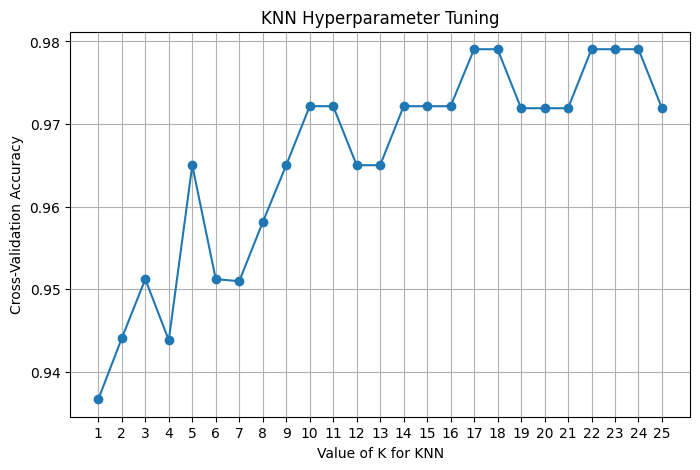

In [16]:
import matplotlib.pyplot as plt

k_range = range(1, 26)

scores = grid.cv_results_['mean_test_score']

plt.figure(figsize=(8, 5))

plt.plot(k_range, scores, marker='o')

plt.xlabel('Value of K for KNN')
plt.ylabel('Cross-Validation Accuracy')
plt.title('KNN Hyperparameter Tuning')

plt.grid(True)
plt.xticks(k_range)
plt.show()

### Understanding Model Complexity

- **Training Accuracy:** Measures how well a model performs on the data used for training.
- **Validation Accuracy:** Measures how well the model performs on unseen validation folds during cross-validation.
- **KNN Model Complexity:** In KNN, a smaller value of K generally produces a more complex decision boundary, while a larger value of K produces a smoother decision boundary.

The objective of hyperparameter tuning is to identify a suitable K value that provides good generalization performance.

### 📊 Observations & Results

1. **Effect of Feature Scaling:**
   - StandardScaler brings numerical features to a comparable scale.
   - This is particularly important for KNN because it relies on distance calculations.

2. **Model Evaluation:**
   - KNN and Logistic Regression are evaluated using a separate testing dataset.
   - Accuracy provides an overview of the classification performance.

3. **Hyperparameter Tuning:**
   - Different K values are evaluated using five-fold cross-validation.
   - The K value with the highest mean cross-validation accuracy is selected.

4. **Model Generalization:**
   - Cross-validation helps reduce dependence on a single training-validation split.
   - The final testing dataset is kept separate for evaluating the selected model.

## Making Predictions on Out-of-Sample Data

After selecting the best K value using cross-validation, the trained model can be used to predict the cultivar of new wine samples that were not included in the original dataset.

Each new observation must contain the same 13 chemical features used during model training.

In [17]:
# Get the best model from GridSearchCV
best_model = grid.best_estimator_

print("Selected K:",
      grid.best_params_['knn__n_neighbors'])

# Evaluate the best model on the test dataset
y_pred = best_model.predict(X_test)

print("Final KNN Accuracy:",
      metrics.accuracy_score(y_test, y_pred))

# New wine samples
sample_wine_1 = [
    13.2, 1.78, 2.14, 11.2, 100.0,
    2.65, 2.76, 0.26, 1.28, 4.38,
    1.05, 3.40, 1050.0
]

sample_wine_2 = [
    12.3, 3.05, 2.30, 21.0, 88.0,
    2.20, 2.09, 0.39, 1.63, 2.80,
    0.86, 2.77, 562.0
]

predicted_cultivars = best_model.predict(
    [sample_wine_1, sample_wine_2]
)

print("Predicted classes:", predicted_cultivars)

print("Cultivar names:",
      [wine.target_names[i] for i in predicted_cultivars])

Selected K: 17
Final KNN Accuracy: 1.0
Predicted classes: [0 1]
Cultivar names: [np.str_('class_0'), np.str_('class_1')]


In [18]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



## Limitations of Train-Test Split

- **High Variance:** The evaluation result can depend on which observations are selected for the testing dataset.
- **Limited Evaluation:** A single train-test split evaluates the model using only one particular division of the dataset.
- **K-Fold Cross-Validation:** Divides the training dataset into multiple folds and evaluates the model across different training and validation combinations.
- **Better Model Selection:** Cross-validation provides a more reliable approach for selecting suitable hyperparameters.

**Conclusion:** Train-test splitting is useful for final model evaluation, while cross-validation is useful for hyperparameter tuning and model selection.